In [66]:
# import libraries from tutorial
import matplotlib.pyplot as plt
import pandas as pd #package that does dataframes 
import numpy as np

In [67]:
filtered_will = pd.read_csv('../filtered_catalogue_will.csv') #right click file and copy relative path since HarrisPartI.csv is inside a folder # needs TWO!?!? . infront of file
print(filtered_will) # doing this to visualise what I have

    quantity     cluster_id   preferred_name   NGC    matched_to_harris  \
0   NGC 104      NGC 104      47 Tuc           104    True                
1   NGC 288      NGC 288      NGC 288          288    True                
2   NGC 362      NGC 362      NGC 362          362    True                
3   NGC 1261     NGC 1261     NGC 1261         1261   True                
4   NGC 1851     NGC 1851     NGC 1851         1851   True                
..         ...          ...              ...    ...                 ...   
58  NGC 6981     NGC 6981     M 72             6981   True                
59  NGC 7078     NGC 7078     M 15             7078   True                
60  NGC 7089     NGC 7089     M 2              7089   True                
61  NGC 7099     NGC 7099     M 30             7099   True                
62  Pal 12       Pal 12       Pal 12                  True                

     ID         Name     RA            DEC           L       ...   Age  .1  \
0    NGC 104    47 Tu

In [68]:
filtered_will.columns = filtered_will.columns.str.strip()

In [69]:
filtered_z = filtered_will['Z'] # take the y component
filtered_x = filtered_will['X'] # take the y component
filtered_Rgc = filtered_will['R_gc'] # take the x component 

/opt/miniconda3/lib/python3.14/site-packages/mplcursors/_pick_info.py:54: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  paths = scatter.__wrapped__(*args, **kwargs)


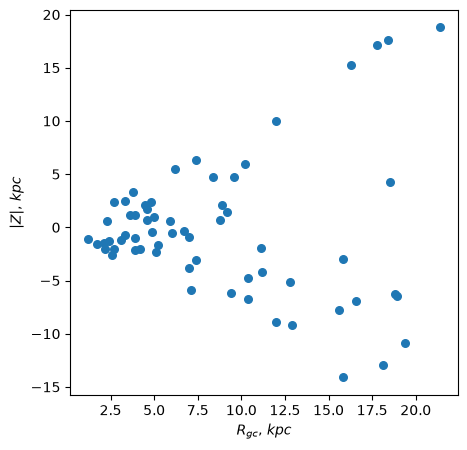

In [70]:
fig, axes = plt.subplots(1, figsize=(5,5)) #I only need one plot
cleanFeHvsAge = axes.scatter(filtered_Rgc, filtered_z, marker='o', s=30, cmap='viridis') # plot components

axes.set_xlabel('$R_{gc}$, $kpc$') # x-axis label
axes.set_ylabel('$|Z|$, $kpc$') # y-axis label

plt.show()


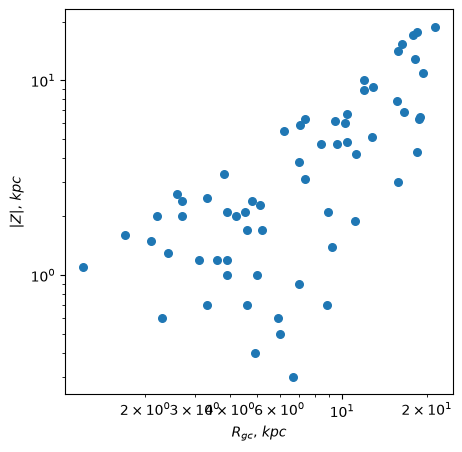

In [71]:
fig, axes = plt.subplots(1, figsize=(5,5)) #I only need one plot
cleanFeHvsAge = axes.scatter(filtered_Rgc, np.abs(filtered_z), marker='o', s=30, cmap='viridis') # plot components

axes.set_xscale('log')
axes.set_yscale('log')

axes.set_xlabel('$R_{gc}$, $kpc$') # x-axis label
axes.set_ylabel('$|Z|$, $kpc$') # y-axis label

plt.show()


# Bring mask over from Age Metal

In [72]:
from astropy.io import ascii 
filtered_catalogue_will = ascii.read("../filtered_catalogue_will.csv", 
                                     format='basic', 
                                     delimiter=',', 
                                     guess=False, 
                                     encoding="utf-8") 

filtered_FeH = filtered_catalogue_will['FeH']
filtered_FeH # to check if the correct column was read in
filtered_Age = filtered_catalogue_will['Age']
filtered_Age # to check if the correct column was read in
filtered_R_G = filtered_catalogue_will['R_G']
filtered_R_G # to check if the correct column was read in

7.4
12.0
9.4
18.1
16.6
--
--
11.1
8.8
21.4
--


In [73]:
x = np.asarray(filtered_FeH, dtype=float)
y = np.asarray(filtered_Age, dtype=float)
rgc = np.asarray(filtered_R_G, dtype=float)

def model(x, a, b, c):
    return c - a * np.exp(b * x)
a, b, c = 11.6, 1.22, 14.6

redcutoff = model(x, a, b, c)        # age the red line gives at each point's [Fe/H]
in_range = (x >= -2.4) & (x <= -0.48)  # so it doesn't go outside the dataset
below = (y < redcutoff) & in_range # things below the red line and between -2.4 and -0.48

below_mask = pd.DataFrame({ 
    'FeH': x[below], 
    'Age': y[below],
    'R_gc': rgc[below],
    'Line_Age': redcutoff[below],
    'Offset': y[below] - redcutoff[below],   # negative = below the line
}).sort_values('Offset').reset_index(drop=True)


# Age Metal comparison on Spatial

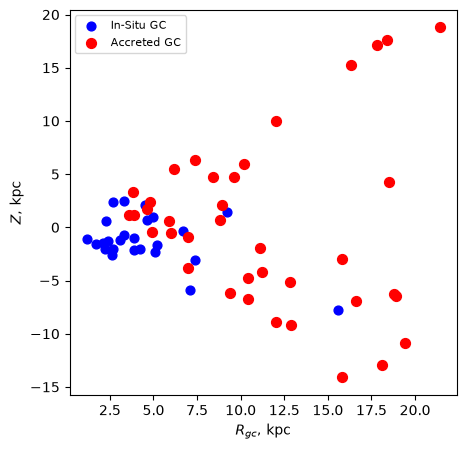

In [74]:
import numpy as np
import matplotlib.pyplot as plt

# Assuming filtered_R_gc, filtered_Z, and below are already defined from your previous steps
z_vals = np.asarray(filtered_z, dtype=float)
rgc_vals = np.asarray(filtered_Rgc, dtype=float)

fig, axes = plt.subplots(1, figsize=(5, 5))

# Plot the "other" points (not in the mask)
axes.scatter(
    rgc_vals[~below], z_vals[~below], 
    marker='o', s=40, color='blue', label='In-Situ GC'
)

# Highlight the 36 "below the line" candidates with red crosses
axes.scatter(
    rgc_vals[below], z_vals[below], 
    marker='o', s=50, color='red', label='Accreted GC'
)

# Optional: If you also want to use absolute values for Z on a log scale later, 
# you'd replace z_vals[below] with np.abs(z_vals[below]) and set scale to 'log'.

axes.set_xlabel(r'$R_{gc}, \, \mathrm{kpc}$')
axes.set_ylabel(r'$Z, \, \mathrm{kpc}$')
axes.legend(fontsize=8)

plt.show()

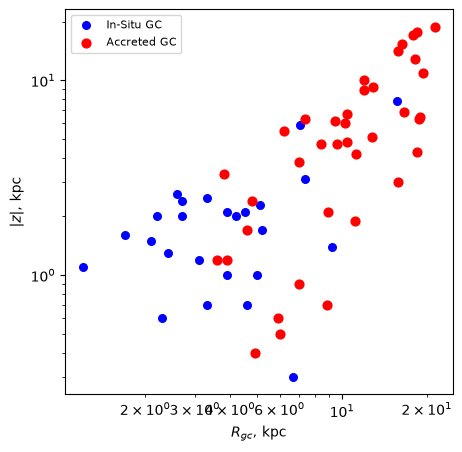

In [75]:
import numpy as np
import matplotlib.pyplot as plt

# Ensure arrays are converted to float and take absolute value of z for log scale
rgc_vals = np.asarray(filtered_Rgc, dtype=float)
z_abs_vals = np.abs(np.asarray(filtered_z, dtype=float))

fig, axes = plt.subplots(1, figsize=(5, 5))

# 1. Plot the "other" points in blue crosses
axes.scatter(
    rgc_vals[~below], z_abs_vals[~below], 
    marker='o', s=30, color='blue', label='In-Situ GC'
)

# 2. Highlight the 36 "below the line" candidates in red crosses
axes.scatter(
    rgc_vals[below], z_abs_vals[below], 
    marker='o', s=40, color='red', label='Accreted GC'
)

# Set log scales
axes.set_xscale('log')
axes.set_yscale('log')

# Axis labels and legend
axes.set_xlabel(r'$R_{gc}, \, \mathrm{kpc}$')
axes.set_ylabel(r'$|z|, \, \mathrm{kpc}$')
axes.legend(fontsize=8)

plt.show()